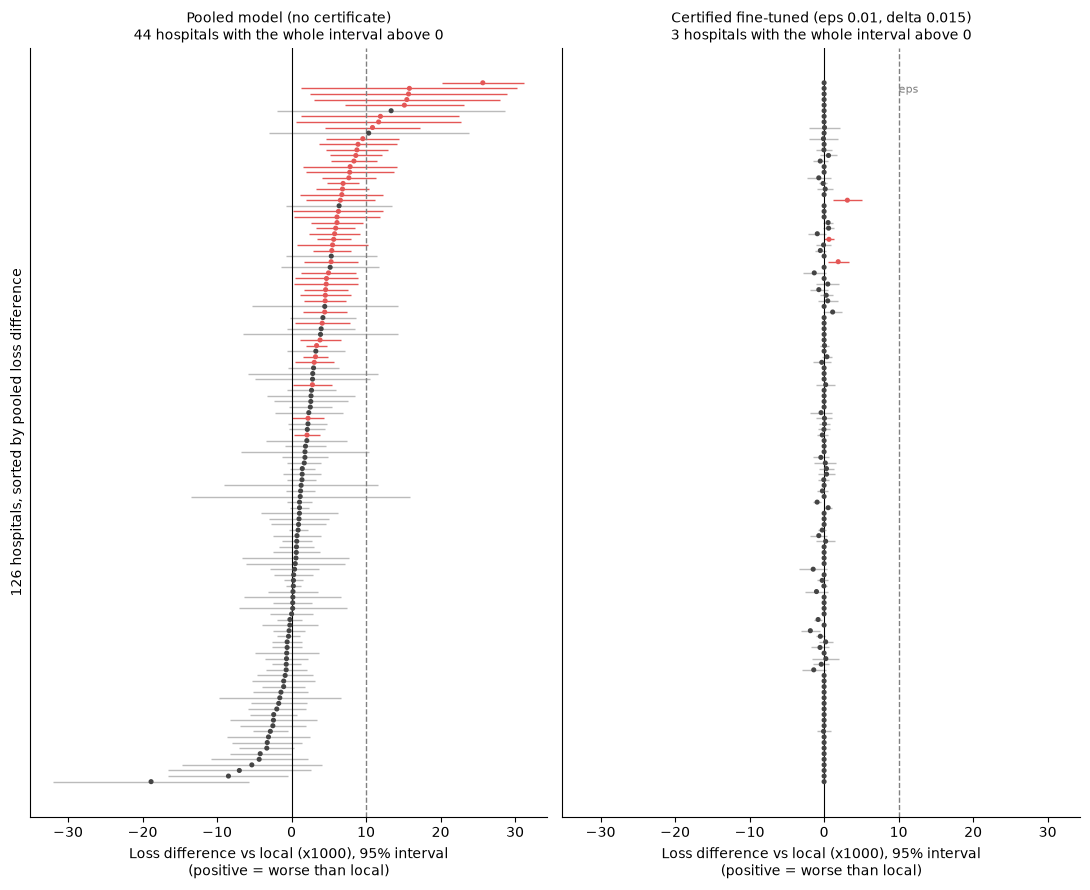

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
R = pd.read_csv("../outputs/tables/cert_full_seed110.csv").copy()
EPS_, DEL_ = 0.01, 0.015
R = R.sort_values("pool_full__diff").reset_index(drop=True)
yy = np.arange(len(R))

fig, ax = plt.subplots(1, 2, figsize=(11, 9), sharey=True)
for a, pre, title in [(ax[0], "pool_full", "Pooled model (no certificate)"),
                      (ax[1], f"cert_ft_e{EPS_}_d{DEL_}", f"Certified fine-tuned (eps {EPS_}, delta {DEL_})")]:
    d, se = 1000 * R[f"{pre}__diff"], 1000 * R[f"{pre}__se"]
    lo, hi = d - 1.96 * se, d + 1.96 * se
    bad = lo > 0
    a.hlines(yy, lo, hi, color=np.where(bad, "#E45756", "#bbbbbb"), lw=1)
    a.scatter(d, yy, s=7, c=np.where(bad, "#E45756", "#444444"), zorder=3)
    a.axvline(0, c="k", lw=0.8); a.axvline(1000 * EPS_, c="grey", ls="--", lw=1)
    a.set_title(f"{title}\n{int(bad.sum())} hospitals with the whole interval above 0", fontsize=10)
    a.set_xlabel("Loss difference vs local (x1000), 95% interval\n(positive = worse than local)")
ax[0].set_ylabel("126 hospitals, sorted by pooled loss difference"); ax[0].set_yticks([])
ax[1].text(1000 * EPS_, len(R) * 0.99, "eps", fontsize=8, ha="left", va="top", color="grey")
ax[1].set_xlim(ax[0].get_xlim())
plt.tight_layout(); plt.savefig("../outputs/figures/fig6_forest.png", dpi=300); plt.savefig("../outputs/figures/fig6_forest.pdf"); plt.show()